In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols, logit
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, r2_score,
                             mean_squared_error, classification_report)

plt.rcParams["font.family"] = 'Apple SD Gothic Neo'

In [9]:
df = pd.read_csv("./test.csv")
print(df.shape)
df = df.iloc[:, 1:]
print(df.shape)
print(df.head())
print(df.info())

(300, 11)
(300, 10)
  line work_shift supplier  oven_temp  humidity  speed  thickness  defect  \
0    A         주간        Y      232.4      50.5   1.23      108.5       0   
1    A         야간        Y      229.3      54.4   1.12      115.2       0   
2    A         야간        X      220.8      48.5   1.27      106.2       0   
3    A         주간        X      234.6      52.2   1.12      117.4       0   
4    A         주간        X      227.0      51.3   1.20      118.7       0   

   rework_min  thickness_dev  
0        14.2            1.5  
1        10.9            5.2  
2        33.8            3.8  
3        31.2            7.4  
4         7.2            8.7  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   line           300 non-null    object 
 1   work_shift     300 non-null    object 
 2   supplier       300 non-null    object 
 3   o

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
oven_temp,300.0,229.559333,5.091650,215.20,225.9750,229.40,232.800,243.00
humidity,300.0,50.042333,7.967516,20.80,45.4000,50.35,55.025,75.40
speed,300.0,1.194967,0.152928,0.78,1.0975,1.20,1.300,1.62
thickness,300.0,106.435000,9.613776,83.20,99.7750,106.60,112.925,131.30
defect,300.0,0.136667,0.344069,0.00,0.0000,0.00,0.000,1.00
rework_min,300.0,28.733333,21.953154,4.60,16.4000,23.40,34.025,173.70
thickness_dev,300.0,8.214333,6.121722,0.10,3.2750,6.90,12.600,26.80


In [14]:
ALPHA = 0.05
LOG = []

def verdict(name, p, h0, reject_msg = "", keep_msg = "", stat = None,
            alpha = ALPHA):
    rejected = p < alpha
    sign = "<" if rejected else ">="
    print(f"-----[{name}]-----")
    print(f"   H0: {h0}   ")
    if stat is not None:
        print(f"검정통계량 = {stat:.4f}")
    print(f"   p-value = {p:.6f}   {sign}   alpha = {alpha}")
    if rejected:
        print(f"귀무가설 기각 : {reject_msg}")
    else:
        print(f"귀무가설 기각 못한 : {keep_msg}")
    LOG.append({"검정": name, "p-value": p, "판결": "기각" if rejected else "기각못함"})
verdict("테스트", p = 0.03, h0 = "차이없다.", reject_msg = "차이가있다.",
        keep_msg = "차이가 있다고 단정 못함")
LOG.clear()

-----[테스트]-----
   H0: 차이없다.   
   p-value = 0.030000   <   alpha = 0.05
귀무가설 기각 : 차이가있다.


alpha = 0.1  -> 잘못 기각한 비율(1종 오류율) = 0.105
alpha = 0.05 -> 잘못 기각한 비율(1종 오류율) = 0.055
alpha = 0.01 -> 잘못 기각한 비율(1종 오류율) = 0.012


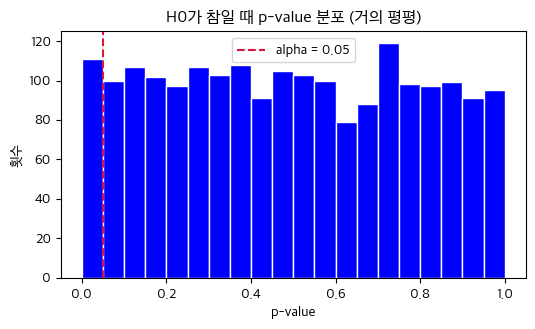

In [15]:
sim = np.random.default_rng(0)
TRIALS = 2000

def simulate_pvalues(true_diff, n, sd = 8):
    a = sim.normal(110, sd, (TRIALS, n))
    b = sim.normal(110 + true_diff, sd, (TRIALS, n))
    return stats.ttest_ind(a, b, axis = 1).pvalue

p_h0 = simulate_pvalues(0, 30)

for a in [0.10, 0.05, 0.01]:
    print(f"alpha = {a:<4} -> 잘못 기각한 비율(1종 오류율) = {(p_h0 < a).mean():.3f}")

plt.figure(figsize = (6, 3.2))
plt.hist(p_h0, bins = 20, color = "blue", edgecolor = "white")
plt.axvline(0.05, color = "crimson", ls = "--", label = "alpha = 0.05")
plt.title("H0가 참일 때 p-value 분포 (거의 평평)")
plt.xlabel("p-value")
plt.ylabel("횟수")
plt.legend()
plt.show()

 표본크기 n  검정력(1-B)  2종오류(B)
      5    0.0920   0.9080
     10    0.1750   0.8250
     20    0.3320   0.6680
     30    0.4775   0.5225
     50    0.6875   0.3125
    100    0.9420   0.0580


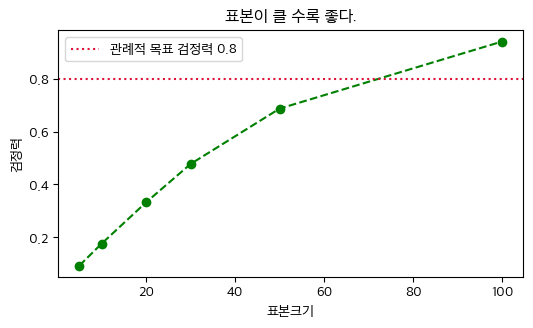

In [16]:
rows = []
for n in [5, 10, 20, 30, 50, 100]:
    p = simulate_pvalues(true_diff = 4, n = n)
    power = (p < 0.05).mean()
    rows.append({"표본크기 n": n, "검정력(1-B)": power, "2종오류(B)": 1 - power})
power_df = pd.DataFrame(rows)
print(power_df.to_string(index = False))

plt.figure(figsize = (6, 3.2))
plt.plot(power_df["표본크기 n"], power_df["검정력(1-B)"], "o--", color = "green")
plt.axhline(0.8, color = "crimson", ls = ":", label = "관례적 목표 검정력 0.8")
plt.title("H0가 참일 때 p-value 분포 (거의 평평)")
plt.xlabel("표본크기")
plt.ylabel("검정력")
plt.title("표본이 클 수록 좋다.")
plt.legend()
plt.show()

In [18]:
p = simulate_pvalues(true_diff = 4, n = 30)
for a in [0.10, 0.05, 0.01]:
    print(f"alpha = {a:<4}->1종오류확률 = {a:<4} | 검정력 = {(p < a).mean():.3f} | 2종오류베타 = {(p >= a).mean():.3f}")

alpha = 0.1 ->1종오류확률 = 0.1  | 검정력 = 0.616 | 2종오류베타 = 0.384
alpha = 0.05->1종오류확률 = 0.05 | 검정력 = 0.484 | 2종오류베타 = 0.516
alpha = 0.01->1종오류확률 = 0.01 | 검정력 = 0.255 | 2종오류베타 = 0.745


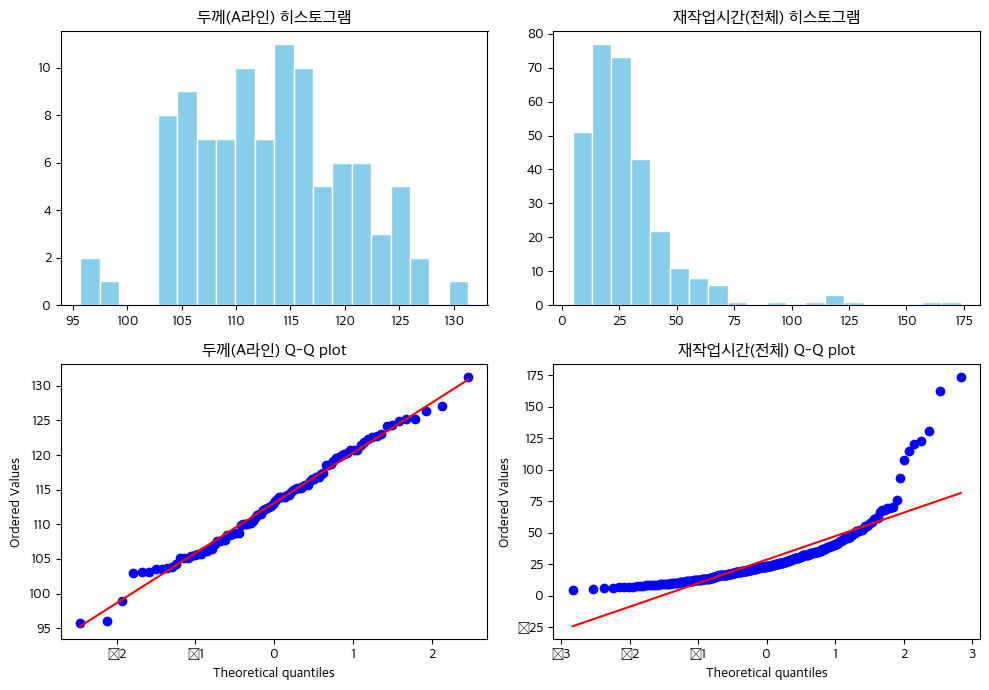

In [22]:
fig, ax = plt.subplots(2, 2, figsize = (10, 7))
for col, (var, title) in enumerate([("thickness", "두께(A라인)"),
                                    ("rework_min", "재작업시간(전체)")]):
    x = df.loc[df.line == "A", var] if var == "thickness" else df[var]
    ax[0, col].hist(x, bins = 20, color = "skyblue", edgecolor = "white")
    ax[0, col].set_title(f"{title} 히스토그램")
    stats.probplot(x, dist = "norm", plot = ax[1, col])
    ax[1, col].set_title(f"{title} Q-Q plot")
plt.tight_layout()
plt.show()

In [24]:
l_data = np.array([119, 110, 108, 120, 117, 109, 96, 104, 123, 113, 129,
                   106, 93, 92, 102])
print(stats.shapiro(l_data))

for name, x in [("A라인두께", df.loc[df.line == "A", "thickness"]),
                ("B라인두께", df.loc[df.line == "B", "thickness"]),
                ("C라인두께", df.loc[df.line == "C", "thickness"]),
                ("재작업시간", df["rework_min"])]:
    res = stats.shapiro(x)
    verdict(f"정규성: {name}", res.pvalue, "데이터는 정규분포를(pvalue가 0.05보다 크면 따른다/ 크지않으면 따르지않는다)",
            reject_msg = "정규분포가 아니다", keep_msg = "정규분포라고 볼 수 있다.",
            stat = res.statistic)

ShapiroResult(statistic=0.9740516543388367, pvalue=0.9128594994544983)
-----[정규성: A라인두께]-----
   H0: 데이터는 정규분포를(pvalue가 0.05보다 크면 따른다/ 크지않으면 따르지않는다)   
검정통계량 = 0.9907
   p-value = 0.719578   >=   alpha = 0.05
귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
-----[정규성: B라인두께]-----
   H0: 데이터는 정규분포를(pvalue가 0.05보다 크면 따른다/ 크지않으면 따르지않는다)   
검정통계량 = 0.9891
   p-value = 0.594479   >=   alpha = 0.05
귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
-----[정규성: C라인두께]-----
   H0: 데이터는 정규분포를(pvalue가 0.05보다 크면 따른다/ 크지않으면 따르지않는다)   
검정통계량 = 0.9850
   p-value = 0.319120   >=   alpha = 0.05
귀무가설 기각 못한 : 정규분포라고 볼 수 있다.
-----[정규성: 재작업시간]-----
   H0: 데이터는 정규분포를(pvalue가 0.05보다 크면 따른다/ 크지않으면 따르지않는다)   
검정통계량 = 0.7161
   p-value = 0.000000   <   alpha = 0.05
귀무가설 기각 : 정규분포가 아니다
